# 04 · The 2020 test year

**In the story** (notebook 00, §4.1 and §6): the pre-registered SPX 2020 test is inconclusive. The minimum-variance delta removed 18.5% of the squared error for calls and 12.0% for puts, but the March 2020 crash leaves 95% intervals spanning about −0.4 to +0.46. All 11 pre-specified robustness variants agree on the verdict, though wide intervals limit what that agreement establishes. This notebook shows the verdict, why the intervals are so wide, and what went wrong after the crash.

The confirmatory question (`analysis_plan.md` §1, §8) is whether, in 2020, Hull and White's minimum-variance delta (R2) reduces next-session squared hedging error relative to the Black–Scholes delta (R1). Does it also beat Ruf and Wang's scaling rules: the fixed 0.9·δ for calls and 1.1·δ for puts (R3), and a fitted a·δ (R4)?

Each 2020 month is hedged with coefficients fitted on the 12 months before it. A training pair must end before the test month's first session. The plan was committed (77b030e) before any 2020 hedging outcome was computed, and 2020 was opened in one logged run (implementation b661d6a).

Gain of rule X over rule Y = 1 − Σe²_X/Σe²_Y on the same pairs; a Gain of 0.10 means 10% less squared error.

H1 requires the 95% lower bound of the Gain over R1 to exceed 0 for calls *and* puts.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
v = pd.read_csv(R / "2020/verdict.csv")
v.round(3)

,variant,verdict,H1,G_C,G_C_lo,G_C_hi,C_vs_R3,C_vs_R4,G_P,G_P_lo,G_P_hi,P_vs_R3,P_vs_R4
0,primary,Inconclusive,False,0.185,-0.357,0.463,not distinguished,not distinguished,0.120,-0.447,0.457,not distinguished,not distinguished
1,A,Inconclusive,False,0.147,-0.399,0.458,not distinguished,not distinguished,0.219,-0.547,0.552,not distinguished,not distinguished
2,B,Inconclusive,False,0.178,-0.377,0.459,not distinguished,not distinguished,0.119,-0.405,0.446,not distinguished,not distinguished
3,P-bid,Inconclusive,False,0.149,-0.246,0.370,not distinguished,not distinguished,0.101,-0.317,0.370,not distinguished,not distinguished
4,P-ask,Inconclusive,False,0.140,-0.247,0.392,not distinguished,not distinguished,0.100,-0.357,0.414,not distinguished,not distinguished
5,F,Inconclusive,False,0.178,-0.088,0.329,not distinguished,not distinguished,0.145,-0.135,0.322,R2 beats,R2 beats
6,W36,Inconclusive,False,0.178,-0.249,0.395,not distinguished,not distinguished,0.142,-0.310,0.412,not distinguished,not distinguished
7,W60,Inconclusive,False,0.176,-0.231,0.384,not distinguished,not distinguished,0.144,-0.285,0.400,not distinguished,not distinguished
8,S3,Inconclusive,False,0.095,-0.356,0.412,not distinguished,not distinguished,-0.028,-0.480,0.384,not distinguished,not distinguished
9,rest of 2020,Inconclusive,False,0.126,-0.235,0.344,not distinguished,R2 beats,0.161,-0.194,0.343,not distinguished,not distinguished


In [3]:
g = pd.read_csv(R / "2020/gains.csv")
prim = g[(g.variant == "primary") & (g.rule == "R2") & g.base.isin(["R1", "R3", "R4"])]
prim[["cp", "rule", "base", "gain", "lo", "hi", "p_plus", "p_minus", "pairs"]].round(3)

,cp,rule,base,gain,lo,hi,p_plus,p_minus,pairs
0,C,R2,R1,0.185,-0.357,0.463,0.243,0.757,489199
1,C,R2,R3,0.005,-0.207,0.185,0.506,0.495,489199
2,C,R2,R4,0.040,-0.074,0.163,0.253,0.747,489199
9,P,R2,R1,0.120,-0.447,0.457,0.314,0.686,568256
10,P,R2,R3,0.101,-0.112,0.303,0.222,0.778,568256
11,P,R2,R4,0.182,-0.080,0.319,0.064,0.937,568256


The verdict is "Inconclusive". The minimum-variance delta (R2) reduces squared hedging error by 18.5% for calls and 12.0% for puts, relative to the Black–Scholes delta (R1). The session-block bootstrap intervals are [−0.36, 0.46] and [−0.45, 0.46]. H1 is not supported, and nothing is rejected: the data cannot tell a 20% improvement from none.

Against the scaling rules, all four comparisons are "not distinguished": the fixed 0.9/1.1 scaling (R3) and the fitted scaling a·δ (R4), for calls and puts.

All 11 pre-specified robustness variants give the same verdict:
- the options' own index level (A);
- the vendor's level (B);
- bid-only and ask-only marks;
- the frozen 2019 fit (F);
- 36- and 60-month windows;
- the spread screen (S3);
- the rest of 2020 without the stress period;
- the two vanished-quote scenarios.

Wide intervals limit what that agreement establishes. The variants' point Gains move more; notebook 05 gives the detail. In three variant comparisons the minimum-variance delta does beat a scaling rule (F for puts against both; the rest of 2020 for calls against R4), never in the primary.

The lower bounds sit 0.54 and 0.57 below the point Gains. Given these interval widths, only a Gain above roughly 0.5 could have cleared zero: about twice the 0.23–0.26 that Hull and White report.

The intervals are wide because the error is concentrated. In March 2020 the index moved by up to 12% a day, so squared errors on those days are about 100 times those of a calm day.

In [4]:
d = pd.read_csv(R / "2020/descriptives.csv")
d[d.rule.isin(["R0", "R1", "R2", "R3", "R4"])][["cp", "rule", "pairs", "effectiveness_vs_R0", "rms_dollars_per_contract", "stress_share_R1"]].round(3)

,cp,rule,pairs,effectiveness_vs_R0,rms_dollars_per_contract,stress_share_R1
0,C,R0,489199,0.000,2981.225,0.802
1,C,R1,489199,0.918,824.657,0.802
2,C,R2,489199,0.933,727.423,0.802
3,C,R3,489199,0.933,738.050,0.802
4,C,R4,489199,0.930,750.690,0.802
7,P,R0,568256,0.000,3889.304,0.858
8,P,R1,568256,0.947,893.522,0.858
9,P,R2,568256,0.954,804.248,0.858
10,P,R3,568256,0.948,860.489,0.858
11,P,R4,568256,0.943,890.371,0.858


In [5]:
for cp in "CP":
    t = pd.read_csv(R / f"2020/top_sessions_{cp}.csv")
    print(cp, "top-10 sessions' share of Black–Scholes squared error:", round(t.share.sum(), 3))
    print(t.assign(session=t.session.str[:10]).round(3).to_string(index=False))

C top-10 sessions' share of Black–Scholes squared error: 0.651
   session  sse_R1  share
2020-03-13   1.272  0.298
2020-03-11   0.264  0.062
2020-06-10   0.226  0.053
2020-03-19   0.198  0.046
2020-03-06   0.196  0.046
2020-03-23   0.176  0.041
2020-03-16   0.153  0.036
2020-03-18   0.105  0.024
2020-03-24   0.097  0.023
2020-03-20   0.096  0.022
P top-10 sessions' share of Black–Scholes squared error: 0.73
   session  sse_R1  share
2020-03-13   1.379  0.229
2020-03-11   0.804  0.134
2020-03-18   0.490  0.081
2020-03-20   0.344  0.057
2020-03-06   0.343  0.057
2020-03-23   0.335  0.056
2020-06-10   0.234  0.039
2020-03-19   0.199  0.033
2020-03-17   0.153  0.025
2020-02-26   0.113  0.019


**Reading.** Black–Scholes already does most of the work. It removes 92% for calls and 95% for puts of the unhedged squared error. The minimum-variance correction adds about 1.5 percentage points of effectiveness for calls and 0.6 for puts by working on what is left.

SPX options are \$100 per index point. In dollars, the correction cuts the RMS hedging error per contract from about \$825 to \$727 for calls, and from \$894 to \$804 for puts.

The stress period (2020-02-24 to 04-30) holds 80% for calls and 86% for puts of the year's Black–Scholes squared error, and ten sessions hold 65–73%. Sessions are dated by day one, so the largest, 2020-03-13 (30% of the calls' error), is the hedge from 13 to 16 March, when the index fell 12%.

The pooled Gain is therefore essentially a statement about March 2020, and a few days decide it.

## The month-by-month picture

Hull and White report the average of monthly Gains; the plan reports both.

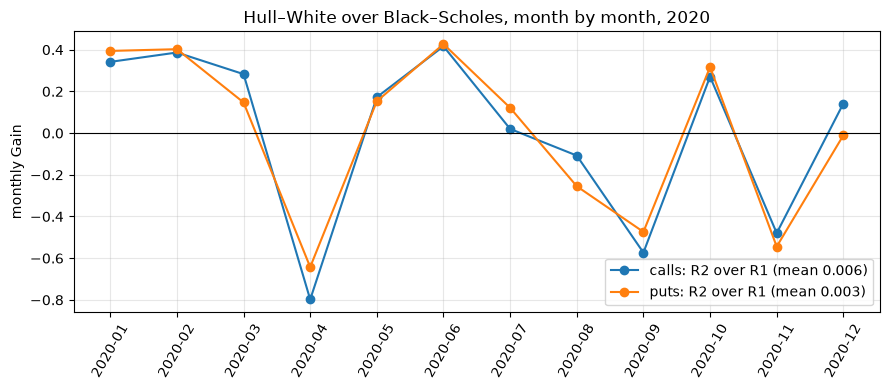

In [6]:
fig, ax = plt.subplots()
for cp, c in (("C", "tab:blue"), ("P", "tab:orange")):
    m = pd.read_csv(R / f"2020/monthly_{cp}.csv")
    ax.plot(m.month, m.G_R2_R1, marker="o", color=c, label=f"{'calls' if cp == 'C' else 'puts'}: R2 over R1 (mean {m.G_R2_R1.mean():.3f})")
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("monthly Gain"); ax.legend(); plt.xticks(rotation=60)
ax.set_title("Hull–White over Black–Scholes, month by month, 2020"); plt.tight_layout()

**Reading.** The correction helps in January–March (Gains of +0.15 to +0.40), June and October. It hurts badly in April (−0.80 for calls), September and November.

The average of monthly Gains is about zero for both types. The pooled +18%/+12% comes from March outweighing the bad months.

## Why April went wrong: the coefficients learn the crash too late

The April fit is the first whose 12-month window contains March 2020. The put coefficients jump (a from −0.34 to −0.45, b from −0.35 to −0.64), so April's hedges apply a crash-sized correction to a market that had calmed.

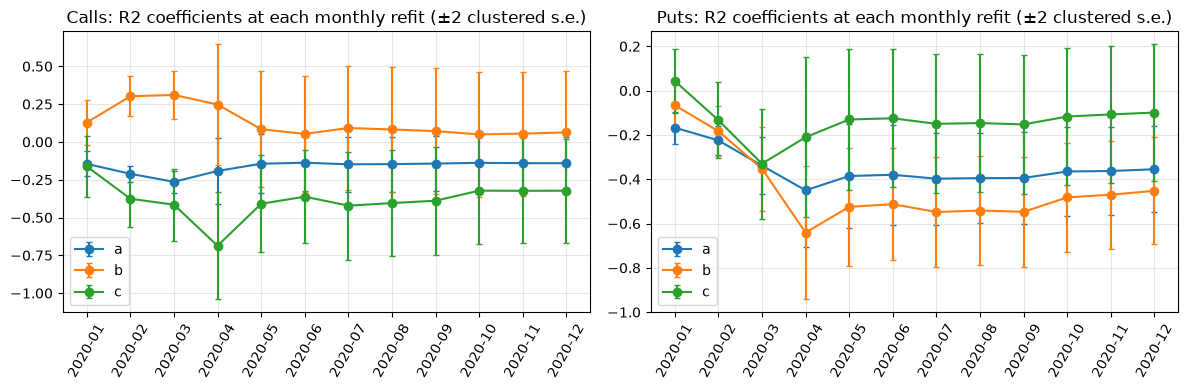

In [7]:
s = pd.read_csv(R / "2020/stability.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, cp in zip(axes, "CP"):
    x = s[(s.rule == "R2") & (s.cp == cp)]
    for k, name in enumerate("abc"):
        y = x[x.k == k]
        ax.errorbar(y.month, y.coef, yerr=2 * y.se_clustered, marker="o", capsize=2, label=name)
    ax.set_title(f"{'Calls' if cp == 'C' else 'Puts'}: R2 coefficients at each monthly refit (±2 clustered s.e.)")
    ax.legend(); ax.tick_params(axis="x", rotation=60)
plt.tight_layout()

In [8]:
c = pd.read_csv(R / "2020/ceiling.csv").pivot_table(index="month", columns="cp", values=["G_R2", "G_ceiling"])
c.round(3)

G_R2        G_ceiling       
cp           C      P         C      P
month                                 
2020-01  0.342  0.394     0.378  0.405
2020-02  0.387  0.403     0.420  0.500
2020-03  0.283  0.147     0.306  0.203
2020-04 -0.798 -0.643     0.054  0.079
2020-05  0.172  0.153     0.231  0.192
2020-06  0.416  0.427     0.454  0.509
2020-07  0.020  0.121     0.132  0.157
2020-08 -0.108 -0.255     0.014  0.002
2020-09 -0.573 -0.474     0.008  0.004
2020-10  0.271  0.317     0.297  0.371
2020-11 -0.480 -0.544     0.010  0.015
2020-12  0.142 -0.011     0.149  0.026

The in-sample ceiling refits R2 on each test month's own pairs: the best a quadratic correction could have done with hindsight.

In the months where R2 failed for both types (April, August, September, November), even the ceiling is small: 0.05–0.08 in April, and at most 0.015 in the other three. The R2 specification could remove only that fraction of Black–Scholes squared error even with hindsight, so an earlier fit of the same specification could gain at most that much; R2 lost 0.11 to 0.80 instead.

The crash in the window is not the whole story. May and June, with March 2020 also in their windows, gained (+0.17 and +0.42 for calls), while September and November lost without a new crash. What decides a month is whether the relation the fit expects is there.

That is a model-risk finding. The rule's value depends on the spot–volatility relation being stable, and in 2020 it was not.

## The crash itself, and the rest of the year

The stress period and the rest of 2020 are bootstrapped in separate strata, so no block crosses between them.

In [9]:
g[g.variant.isin(["stress", "rest of 2020"]) & (g.rule == "R2") & g.base.isin(["R1", "R3", "R4"])][["variant", "cp", "base", "gain", "lo", "hi"]].round(3)

,variant,cp,base,gain,lo,hi
432,stress,C,R1,0.200,-0.596,0.533
433,stress,C,R3,0.005,-0.316,0.236
434,stress,C,R4,0.036,-0.118,0.209
441,stress,P,R1,0.113,-0.664,0.499
442,stress,P,R3,0.109,-0.132,0.348
443,stress,P,R4,0.198,-0.114,0.359
450,rest of 2020,C,R1,0.126,-0.235,0.344
451,rest of 2020,C,R3,0.002,-0.066,0.067
452,rest of 2020,C,R4,0.053,0.032,0.077
459,rest of 2020,P,R1,0.161,-0.194,0.343


Outside the crash the picture is calmer and clearer for calls. R2 beats the fitted scaling rule for calls by 5.3%, with an interval of [0.032, 0.077]. The secondary tests use the full-year family, so this is descriptive.

One crash year cannot settle the question, so the stability evidence comes from repeating the same protocol over 2011–2023 (notebook 06). There the correction usually helps. Its failure in April 2020—a crash entering the training window followed by over-correction—turns out to be one of three recurring failure modes (notebook 00, §6).